# Olist E-Commerce Customer Intelligence
## Day 4 - Exploratory Data Analysis

Looking at how sales, customers, deliveries and reviews behave, using the cleaned tables from Day 2.
Revenue and customer questions use only orders with `in_analysis_scope = True`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
PROCESSED_PATH = "../Data/Processed/"

# CSVs don't keep types, so dates get parsed again and ZIP codes read as text
orders = pd.read_csv(PROCESSED_PATH + "orders_clean.csv",
                     parse_dates=["order_purchase_timestamp", "order_delivered_customer_date",
                                  "order_estimated_delivery_date"])
items = pd.read_csv(PROCESSED_PATH + "order_items_clean.csv")
products = pd.read_csv(PROCESSED_PATH + "products_clean.csv")
customers = pd.read_csv(PROCESSED_PATH + "customers_clean.csv", dtype={"customer_zip_code_prefix": str})
reviews = pd.read_csv(PROCESSED_PATH + "reviews_by_order_clean.csv")
payments = pd.read_csv(PROCESSED_PATH + "payments_clean.csv")

print("orders:", orders.shape)
print("items:", items.shape)

orders: (99441, 18)
items: (112650, 8)


In [3]:
# only the orders that count for revenue / customer analysis
scope = orders[orders["in_analysis_scope"] == True]

# items for those orders, with the product category attached
scope_items = items[items["order_id"].isin(scope["order_id"])]
scope_items = scope_items.merge(products[["product_id", "product_category_name_english"]], on="product_id", how="left")

# total value of each order (sum of its items)
order_value = scope_items.groupby("order_id")["item_revenue"].sum().reset_index(name="order_value")
scope = scope.merge(order_value, on="order_id", how="left")

print("orders in scope:", len(scope))
print("total revenue:", round(scope["order_value"].sum(), 2))

orders in scope: 96470
total revenue: 15418394.83


Question 1: how are revenue and orders changing month by month?

In [4]:
monthly = scope.groupby("purchase_month").agg(
    orders=("order_id", "count"),
    revenue=("order_value", "sum"),
).reset_index()

monthly

,purchase_month,orders,revenue
0,2016-09,1,143.46
1,2016-10,265,46490.66
2,2016-12,1,19.62
3,2017-01,750,127482.37
4,2017-02,1653,271239.32
5,2017-03,2546,414330.95
6,2017-04,2303,390812.40
7,2017-05,3545,566657.40
8,2017-06,3135,490050.37
9,2017-07,3872,566299.08


months left out of the chart: ['2016-09', '2016-10', '2016-12']


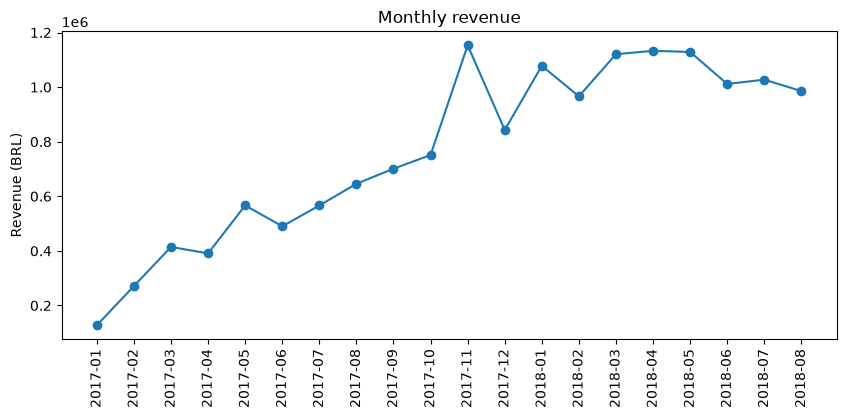

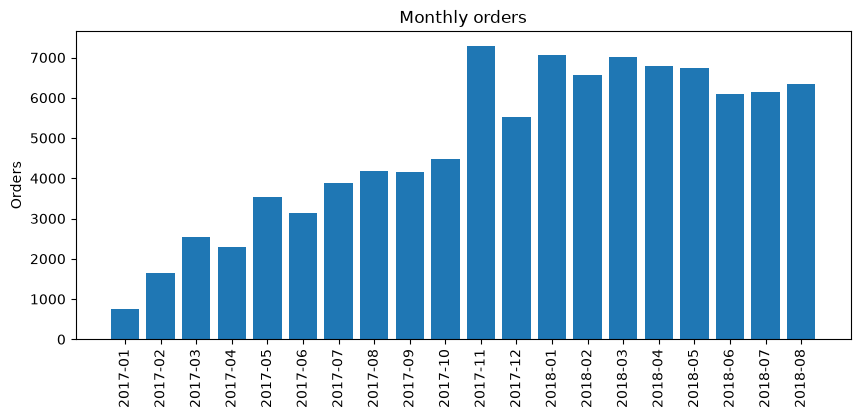

In [5]:

#monthly_trend = monthly[monthly["orders"] >= 100]


monthly_trend = monthly[monthly["purchase_month"] >= "2017-01"]

print("months left out of the chart:", list(monthly[monthly["purchase_month"] < "2017-01"]["purchase_month"]))
fig, ax = plt.subplots()
ax.plot(monthly_trend["purchase_month"], monthly_trend["revenue"], marker="o")
ax.set_title("Monthly revenue")
ax.set_ylabel("Revenue (BRL)")
plt.xticks(rotation=90)
plt.show()

fig, ax = plt.subplots()
ax.bar(monthly_trend["purchase_month"], monthly_trend["orders"])
ax.set_title("Monthly orders")
ax.set_ylabel("Orders")
plt.xticks(rotation=90)
plt.show()


**Question 2:How much does a typical order cost?**

In [6]:
# mean vs median - if the mean is much higher, a few big orders are pulling it up
print("average order value:", round(scope["order_value"].mean(), 2))
print("median order value:", round(scope["order_value"].median(), 2))
scope["order_value"].describe()

average order value: 159.83
median order value: 105.28


count    96470.000000
mean       159.825799
std        218.802007
min          9.590000
25%         61.850000
50%        105.280000
75%        176.260000
max      13664.080000
Name: order_value, dtype: float64

**Question 3: Are most orders small, with a few very large ones?**

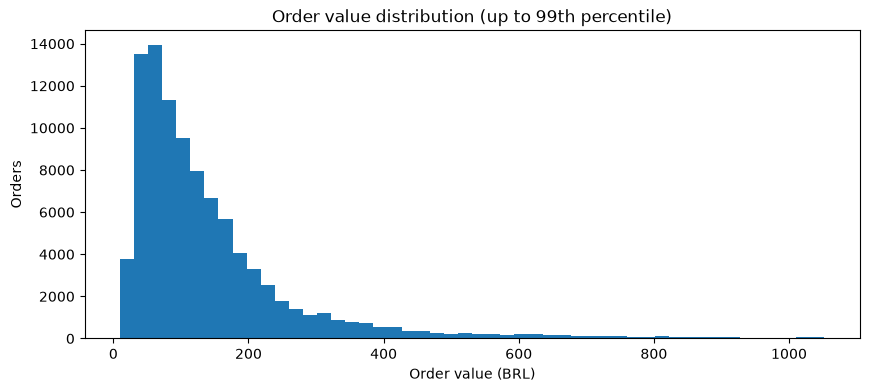

In [7]:
# cutting the chart at the 99th percentile so the few huge orders don't squash everything
cap = scope["order_value"].quantile(0.99)

plt.hist(scope[scope["order_value"] <= cap]["order_value"], bins=50)
plt.title("Order value distribution (up to 99th percentile)")
plt.xlabel("Order value (BRL)")
plt.ylabel("Orders")
plt.show()

**Question 4: Which product categories drive sales, and how concentrated is revenue?**

In [8]:
category = scope_items.groupby("product_category_name_english").agg(
    revenue=("item_revenue", "sum"),
    items_sold=("order_item_id", "count"),
).sort_values("revenue", ascending=False).reset_index()

category["revenue_share_%"] = (category["revenue"] / category["revenue"].sum() * 100).round(2)

print("number of categories:", len(category))
print("top 10 categories share of revenue:", round(category.head(10)["revenue_share_%"].sum(), 2), "%")
category.head(10)

number of categories: 74
top 10 categories share of revenue: 62.4 %


,product_category_name_english,revenue,items_sold,revenue_share_%
0,health_beauty,1412089.53,9465,9.16
1,watches_gifts,1264016.98,5857,8.20
2,bed_bath_table,1225209.26,10953,7.95
3,sports_leisure,1118062.91,8430,7.25
4,computers_accessories,1032603.65,7643,6.70
5,furniture_decor,880329.92,8160,5.71
6,housewares,758392.25,6795,4.92
7,cool_stuff,691680.89,3718,4.49
8,auto,669319.92,4139,4.34
9,garden_tools,567145.68,4268,3.68


**Question 5: What do the top 10 categories look like side by side?**

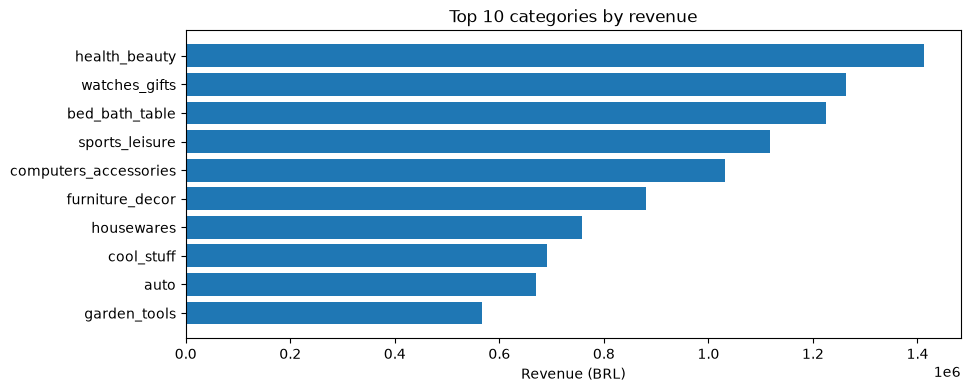

In [9]:
top10 = category.head(10).sort_values("revenue")

plt.barh(top10["product_category_name_english"], top10["revenue"])
plt.title("Top 10 categories by revenue")
plt.xlabel("Revenue (BRL)")
plt.show()

**Question 6: Which states bring in the most orders and revenue?**

In [10]:
scope = scope.merge(customers[["customer_id", "customer_state"]], on="customer_id", how="left")

state = scope.groupby("customer_state").agg(
    orders=("order_id", "count"),
    revenue=("order_value", "sum"),
).sort_values("revenue", ascending=False).reset_index()

state["revenue_share_%"] = (state["revenue"] / state["revenue"].sum() * 100).round(2)
state.head(10)

,customer_state,orders,revenue,revenue_share_%
0,SP,40494,5768518.23,37.41
1,RJ,12350,2055401.57,13.33
2,MG,11354,1818891.67,11.80
3,RS,5344,861278.79,5.59
4,PR,4923,781708.80,5.07
5,SC,3546,595127.78,3.86
6,BA,3256,591137.81,3.83
7,DF,2080,346123.35,2.24
8,GO,1957,334212.35,2.17
9,ES,1995,317657.93,2.06


**Question 7: How uneven is revenue across states?**

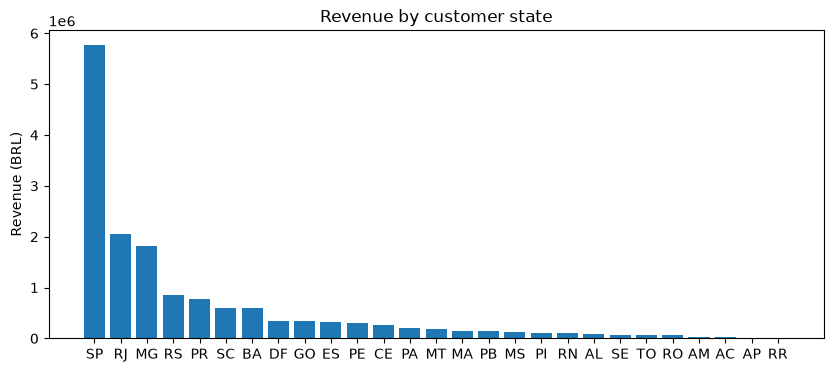

In [11]:
plt.bar(state["customer_state"], state["revenue"])
plt.title("Revenue by customer state")
plt.ylabel("Revenue (BRL)")
plt.show()

**Question 8: What proportion of customers come back and buy again?**

In [12]:
per_customer = scope.groupby("customer_unique_id").agg(
    orders=("order_id", "count"),
    total_spent=("order_value", "sum"),
).reset_index()

repeat = (per_customer["orders"] > 1).sum()

print("customers:", len(per_customer))
print("repeat customers:", repeat)
print("repeat rate:", round(repeat / len(per_customer) * 100, 2), "%")

per_customer["orders"].value_counts().sort_index()

customers: 93350
repeat customers: 2801
repeat rate: 3.0 %


orders
1     90549
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64

**Question 9: How much does a customer spend in total?**

In [13]:
per_customer["total_spent"].describe()

count    93350.000000
mean       165.167593
std        226.300536
min          9.590000
25%         63.010000
50%        107.780000
75%        182.505000
max      13664.080000
Name: total_spent, dtype: float64

**Question 10: How long do deliveries take, and how often are they late?**

In [14]:
print("average delivery days:", round(scope["delivery_days"].mean(), 1))
print("median delivery days:", scope["delivery_days"].median())
print("late delivery rate:", round(scope["is_late"].mean() * 100, 2), "%")

scope["delivery_days"].describe()

average delivery days: 12.1
median delivery days: 10.0
late delivery rate: 6.77 %


count    96470.000000
mean        12.093604
std          9.551380
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: delivery_days, dtype: float64

**Question 11: What does a normal delivery time look like, and how many take extremely long?**

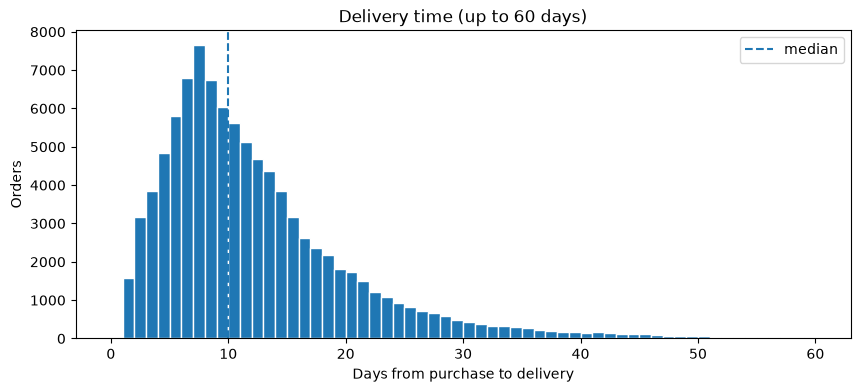

orders over 60 days: 288


In [15]:
plt.hist(scope[scope["delivery_days"] <= 60]["delivery_days"], bins=60, edgecolor="white")
plt.axvline(scope["delivery_days"].median(), linestyle="--", label="median")
plt.title("Delivery time (up to 60 days)")
plt.xlabel("Days from purchase to delivery")
plt.ylabel("Orders")
plt.legend()
plt.show()

# how many orders took longer than 60 days
print("orders over 60 days:", (scope["delivery_days"] > 60).sum())

**Question 12: Are deliveries slower or later in some states than others?**

In [16]:
late_by_state = scope.groupby("customer_state").agg(
    orders=("order_id", "count"),
    late_rate=("is_late", "mean"),
    avg_days=("delivery_days", "mean"),
).sort_values("late_rate", ascending=False).reset_index()

late_by_state["late_rate"] = (late_by_state["late_rate"] * 100).round(2)
late_by_state["avg_days"] = late_by_state["avg_days"].round(1)
late_by_state

,customer_state,orders,late_rate,avg_days
0,AL,397,21.41,24.0
1,MA,717,17.43,21.1
2,SE,335,15.22,21.0
3,PI,476,13.87,19.0
4,CE,1279,13.76,20.8
5,RR,41,12.20,29.0
6,BA,3256,12.16,18.9
7,RJ,12350,12.11,14.8
8,PA,946,11.21,23.3
9,ES,1995,10.73,15.3



**Question 13: How satisfied are customers overall?**

In [17]:
# only the orders that count for revenue / customer analysis
scope = orders[orders["in_analysis_scope"] == True]

# items for those orders, with the product category attached
scope_items = items[items["order_id"].isin(scope["order_id"])]
scope_items = scope_items.merge(products[["product_id", "product_category_name_english"]], on="product_id", how="left")

# total value of each order (sum of its items)
order_value = scope_items.groupby("order_id")["item_revenue"].sum().reset_index(name="order_value")
scope = scope.merge(order_value, on="order_id", how="left")

# adding customer state and review score to each order here, so these merges only happen once
scope = scope.merge(customers[["customer_id", "customer_state"]], on="customer_id", how="left")
scope = scope.merge(reviews[["order_id", "review_score"]], on="order_id", how="left")

print("orders in scope:", len(scope))
print("total revenue:", round(scope["order_value"].sum(), 2))
scope["review_score"].value_counts().sort_index()

orders in scope: 96470
total revenue: 15418394.83


review_score
1.0     9351
2.0     2921
3.0     7916
4.0    18888
5.0    56748
Name: count, dtype: int64

**Question 14: Are reviews mostly positive, or split between very good and very bad?**

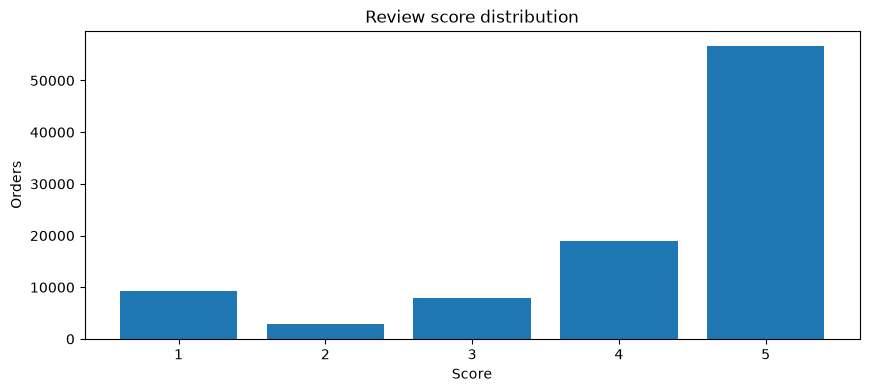

In [18]:
score_counts = scope["review_score"].value_counts().sort_index()
plt.bar(score_counts.index, score_counts.values)
plt.title("Review score distribution")
plt.xlabel("Score")
plt.ylabel("Orders")
plt.show()

**Question 15: Do late orders get worse reviews than on-time orders?**

In [19]:
late_vs_ontime = scope.groupby("is_late")["review_score"].agg(["count", "mean"]).round(2)
late_vs_ontime

,count,mean
is_late,,
False,89443,4.29
True,6381,2.27


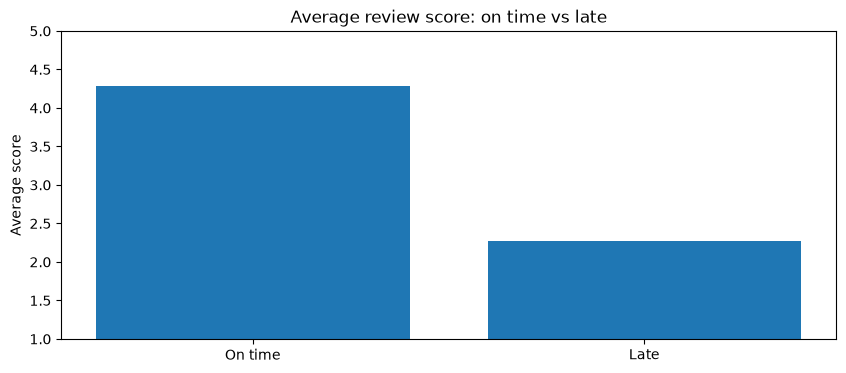

In [20]:
plt.bar(["On time", "Late"], late_vs_ontime["mean"],)
plt.title("Average review score: on time vs late")
plt.ylabel("Average score")
plt.ylim(1, 5)
plt.show()

**Question 16: Does the review score drop as delivery time gets longer?**

In [21]:
# grouping delivery time into ranges to see how the score changes
bins = [0, 7, 14, 21, 30, 60, 1000]
labels = ["0-7", "8-14", "15-21", "22-30", "31-60", "60+"]
scope["delivery_range"] = pd.cut(scope["delivery_days"], bins=bins, labels=labels, include_lowest=True)

by_range = scope.groupby("delivery_range", observed=True)["review_score"].agg(["count", "mean"]).round(2)
by_range

,count,mean
delivery_range,,
0-7,33539,4.41
8-14,36190,4.29
15-21,15264,4.10
22-30,6824,3.49
31-60,3734,2.17
60+,273,2.18


**Question 17: What does that drop look like visually?**

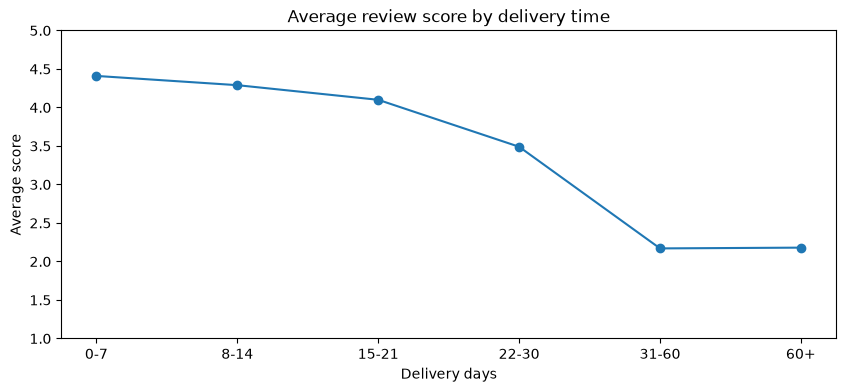

In [22]:
plt.plot(by_range.index.astype(str), by_range["mean"], marker="o")

plt.title("Average review score by delivery time")
plt.xlabel("Delivery days")
plt.ylabel("Average score")
plt.ylim(1, 5)
plt.show()

**Question 18: Are late orders more likely to get the worst possible review?**

In [23]:
# share of 1-star reviews - late vs on time
scope["one_star"] = scope["review_score"] == 1
(scope.groupby("is_late")["one_star"].mean() * 100).round(2)

is_late
False     6.58
True     52.51
Name: one_star, dtype: float64

**Question 19: How do customers prefer to pay?**

In [24]:
# all orders here, not just in scope - this is just about how people pay
payment_share = (payments["payment_type"].value_counts(normalize=True) * 100).round(2)
payment_share

payment_type
credit_card    73.92
boleto         19.04
voucher         5.56
debit_card      1.47
not_defined     0.00
Name: proportion, dtype: float64

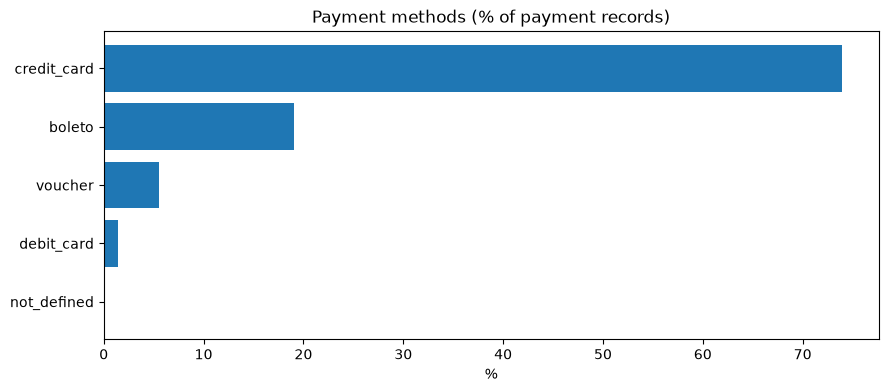

In [25]:
plt.barh(payment_share.index[::-1], payment_share.values[::-1])
plt.title("Payment methods (% of payment records)")
plt.xlabel("%")
plt.show()

**Question 20: Do credit card customers split payments into installments, and how many?**

In [26]:
payments[payments["payment_type"] == "credit_card"]["payment_installments"].describe()

count    76795.000000
mean         3.507155
std          2.850990
min          0.000000
25%          1.000000
50%          3.000000
75%          5.000000
max         24.000000
Name: payment_installments, dtype: float64

**Question 21: Are there unusually large orders worth checking?**

In [27]:
print("orders over 99th percentile value:", (scope["order_value"] > cap).sum())
scope.sort_values("order_value", ascending=False)[["order_id", "order_value", "purchase_month"]].head(5)

orders over 99th percentile value: 965


,order_id,order_value,purchase_month
13013,03caa2c082116e1d31e67e9ae3700499,13664.08,2017-09
64604,736e1922ae60d0d6a89247b851902527,7274.88,2018-07
21524,0812eb902a67711a1cb742b3cdaa65ae,6929.31,2017-02
27501,fefacc66af859508bf1a7934eab1e97f,6922.21,2018-07
3412,f5136e38d1a14a4dbd87dff67da82701,6726.66,2017-05


**Question 22: Which deliveries took the longest, and how were they reviewed?**

In [28]:
scope.sort_values("delivery_days", ascending=False)[["order_id", "delivery_days", "customer_state", "review_score"]].head(5)

,order_id,delivery_days,customer_state,review_score
19029,ca07593549f1816d26a572e06dc1eab6,209.0,ES,NaN
53963,1b3190b2dfa9d789e1f14c05b647a14a,208.0,RJ,2.0
59778,440d0d17af552815d15a9e41abe49359,195.0,PA,1.0
68207,2fb597c2f772eca01b1f5c561bf6cc7b,194.0,PI,4.0
86459,285ab9426d6982034523a855f55a885e,194.0,SE,1.0


## Observations

**Sales over time**
- Monthly orders grew from 750 in 2017-01 to a peak of 7,288 in 2017-11, then stayed around 6,000-7,000 a month through 2018.
- 2016-09, 2016-10 and 2016-12 were left out of the trend charts because 2016 is patchy (no orders at all in 2016-11 and only 1 in 2016-12).

**Order value**
- Average order value is 159.83 BRL but the median is 105.28 BRL, so a small number of large orders (max 13,664.08) pull the average up.

**Categories**
- 74 categories. The top 10 make up 62.4% of revenue, led by health_beauty (9.16%), watches_gifts (8.20%) and bed_bath_table (7.95%).

**Geography**
- SP alone brings 37.41% of revenue. SP, RJ and MG together make up 62.54%.

**Customers**
- 93,350 customers, only 2,801 (3.0%) bought more than once. Frequency will be weak in RFM.
- Median total spend per customer is 107.78 BRL, almost the same as a single median order.

**Delivery**
- Orders take 12.1 days on average to arrive, with a median of 10 days.
- 6.77% of orders arrived after the estimated date.
- 288 orders took more than 60 days; the slowest took 209 days.
- The highest late rates are in AL (21.41%), MA (17.43%) and SE (15.22%), all smaller states. SP, the largest market, has one of the lowest late rates (4.49%) and the fastest average delivery (8.3 days).

**Reviews**
- The average review score is 4.16 out of 5, based on 95,824 orders with a review.
- 59.22% of reviews are 5 stars, but 12.81% are 1 or 2 stars.

**Delivery vs reviews**
- On-time orders average 4.29 stars, while late orders average 2.27 stars.
- The score drops steadily with delivery time: 4.41 for 0-7 days, 4.29 for 8-14, 4.10 for 15-21, 3.49 for 22-30, and about 2.2 beyond 30 days.
- 52.51% of late orders get a 1-star review, compared with 6.58% of on-time orders.

**Payments**
- Credit card is the most used payment method (73.92% of payment records), followed by boleto (19.04%), voucher (5.56%) and debit card (1.47%).
- Credit card customers use a median of 3 installments, up to a maximum of 24.

**Anomalies**
- 965 orders are above the 99th percentile in value; the largest is 13,664.08 BRL (2017-09).
- The slowest delivery took 209 days. Four of the five slowest orders that have a review scored 1 or 2 stars.
- Some credit card payments show 0 installments, which should be at least 1. Worth checking in cleaning.